
# TP : Prédire le prix de location de logements à Antananarivo avec une régression linéaire multiple

## 🎯 Objectifs pédagogiques

- Appliquer un pipeline de prétraitement complet sur un jeu de données semi-structuré.
- Gérer les variables qualitatives, les valeurs manquantes, la multicolinéarité et la scalabilité.
- Construire, tester et évaluer un modèle de régression linéaire multiple.
- Déployer le modèle dans une application Python Streamlit avec interface utilisateur.

## 🗂️ Jeu de données

Le jeu de données doit être collecté ou scrappé dans les pages comme Facebook. Il doit comporter les colonnes suivantes :

- `quartier` (catégorielle)
- `superficie` (numérique)
- `nombre_chambres` (numérique)
- `douche_wc`(interieur ou exterieur)
- `type_d_acces` (sans, moto, voiture, voiture_avec_par_parking)
- `meublé` (booléen:  oui ou non)
- `état_général` (catégorielle : bon, moyen, mauvais)
- `loyer_mensuel` (target)

## 🧪 Étapes du TP

### 📌 Partie 1 : Préparation des données
- Lecture du dataset brut
- Gestion des valeurs manquantes
- Encodage des variables catégorielles
- Création de variables dérivées
- Détection et suppression des variables fortement corrélées
- Standardisation et normalisation

### 📌 Partie 2 : Modélisation

- Séparation train/test
- Implémentation de la régression linéaire multiple
- Évaluation : R², RMSE
- Vérification des hypothèses d'élligibilité de la régression linéaire multiple (surtout sur les erreurs)

### 📌 Partie 3 : Optimisation du modèle

- Sélection de variables : backward elimination, RFE (à documenter)

### 📌 Partie 4 : Déploiement d'une application Streamlit

- Interface de saisie utilisateur
- Affichage du loyer prédit
- Visualisation des poids des variables
- Affichage sur la carte interactive

## 🧭 Carte interactive (option avancée)

Utiliser `streamlit-folium` pour permettre à l'utilisateur de cliquer sur une carte et de récupérer les coordonnées GPS. À partir de ces coordonnées, déterminer automatiquement le quartier en utilisant un fichier GeoJSON ou un système de polygones avec `geopandas`.

## 🔧 Technologies à utiliser

- `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`, `joblib`
- `streamlit`, `folium`, `streamlit-folium`
- Optionnel : `geopandas`, `shapely`

## 💡 Bonus

- Carte interactive avec folium
- Simuler des données additionnelles (pollution, sécurité)
- Tri automatique des caractéristiques influentes



## ℹ️ Note sur le jeu de données utilisé dans ce notebook

L'énoncé demande un jeu de données **collecté ou scrappé** (par ex. sur des groupes Facebook
d'annonces immobilières). Le scraping de Facebook pose en pratique plusieurs problèmes (données
personnelles, conditions d'utilisation de la plateforme, authentification requise) et ne peut pas
être automatisé de manière fiable ici.

Pour pouvoir dérouler **tout le pipeline ML de bout en bout**, ce notebook utilise donc un jeu de
données **simulé mais réaliste** : les 16 quartiers utilisés sont de vrais quartiers d'Antananarivo,
avec des coordonnées GPS approximatives et des niveaux de loyer cohérents avec leur standing
(quartiers d'affaires comme Ivandry/Ankorondrano plus chers, quartiers périphériques comme
Itaosy/Tanjombato moins chers). Des valeurs manquantes, doublons et valeurs aberrantes ont été
injectés volontairement pour que les étapes de nettoyage de la Partie 1 aient un intérêt réel.

**Pour utiliser vos vraies données collectées**, il suffit de remplacer le fichier
`data/logements_antananarivo.csv` par votre propre CSV en gardant les mêmes noms de colonnes
(`quartier, superficie, nombre_chambres, douche_wc, type_d_acces, meuble, etat_general,
latitude, longitude, loyer_mensuel`) — tout le reste du notebook fonctionne à l'identique.


## 🔧 Import des librairies

In [70]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.feature_selection import RFE

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

import joblib
import os

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
os.makedirs("model", exist_ok=True)

# 📌 Partie 1 : Préparation des données

## 1.1 Chargement et exploration du dataset

In [44]:
df = pd.read_csv("data/logements_antananarivo.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (658, 10)


,quartier,superficie,nombre_chambres,douche_wc,type_d_acces,meuble,etat_general,latitude,longitude,loyer_mensuel
0,Tanjombato,74.2,3.0,exterieur,sans,non,moyen,-18.957714,47.517431,448500.0
1,Ambohijatovo,52.6,3.0,interieur,moto,non,bon,-18.911561,47.517822,961000.0
2,Ivandry,58.7,3.0,interieur,voiture_avec_parking,oui,bon,-18.871455,47.527578,2961600.0
3,Isoraka,50.5,3.0,interieur,moto,oui,moyen,-18.914198,47.520014,1082200.0
4,Analakely,32.4,2.0,NaN,sans,non,bon,-18.905666,47.531178,696600.0


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 658 entries, 0 to 657
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   quartier         658 non-null    str    
 1   superficie       639 non-null    float64
 2   nombre_chambres  645 non-null    float64
 3   douche_wc        631 non-null    str    
 4   type_d_acces     645 non-null    str    
 5   meuble           658 non-null    str    
 6   etat_general     626 non-null    str    
 7   latitude         658 non-null    float64
 8   longitude        658 non-null    float64
 9   loyer_mensuel    658 non-null    float64
dtypes: float64(5), str(5)
memory usage: 73.6 KB


In [46]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
quartier,658,16,Ambatobe,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
superficie,639.0,NaN,NaN,NaN,58.640219,33.499311,12.0,41.2,57.5,72.55,421.7
nombre_chambres,645.0,NaN,NaN,NaN,2.651163,1.218715,1.0,2.0,3.0,3.0,6.0
douche_wc,631,2,interieur,356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_d_acces,645,4,sans,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meuble,658,2,non,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
etat_general,626,3,bon,294,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,658.0,NaN,NaN,NaN,-18.894687,0.02498,-18.9607,-18.9107,-18.898986,-18.873207,-18.845516
longitude,658.0,NaN,NaN,NaN,47.51907,0.018414,47.452111,47.516662,47.522555,47.527887,47.556285
loyer_mensuel,658.0,NaN,NaN,NaN,1026636.62614,752529.074229,73600.0,480350.0,814150.0,1394800.0,4668800.0



## 1.2 Détection et suppression des doublons

Certaines annonces peuvent être republiées plusieurs fois (republication automatique sur
Facebook, doublons de scraping). On les détecte avec `duplicated()` et on les supprime.


In [47]:
n_doublons = df.duplicated().sum()
print(f"Nombre de lignes dupliquées : {n_doublons}")
df = df.drop_duplicates().reset_index(drop=True)
print("Nouvelle dimension après suppression des doublons :", df.shape)

Nombre de lignes dupliquées : 8
Nouvelle dimension après suppression des doublons : (650, 10)



## 1.3 Gestion des valeurs manquantes

On commence par visualiser le volume de valeurs manquantes par colonne, puis on choisit une
stratégie d'imputation adaptée au type de variable :
- variables **numériques** (`superficie`, `nombre_chambres`) → imputation par la **médiane**
  (plus robuste que la moyenne face aux valeurs extrêmes) ;
- variables **catégorielles** (`douche_wc`, `type_d_acces`, `etat_general`) → imputation par le
  **mode** (valeur la plus fréquente).


etat_general       32
douche_wc          26
superficie         19
nombre_chambres    13
type_d_acces       13
dtype: int64


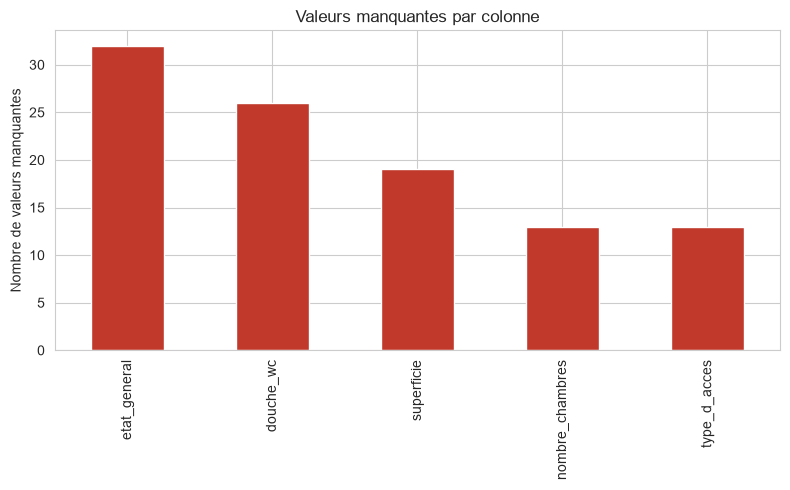

In [48]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

fig, ax = plt.subplots()
missing.plot(kind="bar", ax=ax, color="#c0392b")
ax.set_ylabel("Nombre de valeurs manquantes")
ax.set_title("Valeurs manquantes par colonne")
plt.tight_layout()
plt.show()

In [71]:
df["superficie"] = df["superficie"].fillna(df["superficie"].median())
df["nombre_chambres"] = df["nombre_chambres"].fillna(df["nombre_chambres"].median())
df["douche_wc"] = df["douche_wc"].fillna(df["douche_wc"].mode()[0])
df["type_d_acces"] = df["type_d_acces"].fillna(df["type_d_acces"].mode()[0])
df["etat_general"] = df["etat_general"].fillna(df["etat_general"].mode()[0])

assert df.isna().sum().sum() == 0, "Il reste des valeurs manquantes !"
print("✅ Plus aucune valeur manquante.")

✅ Plus aucune valeur manquante.



## 1.4 Détection et traitement des valeurs aberrantes (outliers)

On utilise la méthode de l'**écart interquartile (IQR)** sur `superficie` : toute valeur
au-delà de `Q3 + 1.5×IQR` est considérée comme aberrante (erreur de saisie ou fausse annonce).


Borne supérieure (Q3 + 1.5*IQR) = 115.7 m² -> 9 outlier(s) détecté(s)


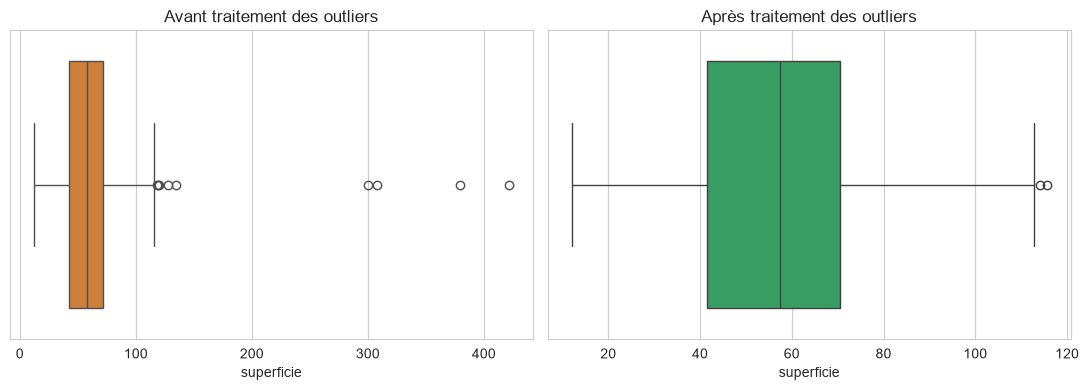

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df["superficie"], ax=axes[0], color="#e67e22")
axes[0].set_title("Avant traitement des outliers")

q1, q3 = df["superficie"].quantile([0.25, 0.75])
iqr = q3 - q1
borne_sup = q3 + 1.5 * iqr
n_outliers = (df["superficie"] > borne_sup).sum()
print(f"Borne supérieure (Q3 + 1.5*IQR) = {borne_sup:.1f} m² -> {n_outliers} outlier(s) détecté(s)")

df = df[df["superficie"] <= borne_sup].reset_index(drop=True)

sns.boxplot(x=df["superficie"], ax=axes[1], color="#27ae60")
axes[1].set_title("Après traitement des outliers")
plt.tight_layout()
plt.show()


## 1.5 Création de variables dérivées

On crée `superficie_par_chambre`, un indicateur du "confort spatial" d'un logement (plus la
valeur est élevée, plus les chambres sont spacieuses en moyenne).


In [51]:
df["superficie_par_chambre"] = df["superficie"] / df["nombre_chambres"]
df[["superficie", "nombre_chambres", "superficie_par_chambre"]].head()

,superficie,nombre_chambres,superficie_par_chambre
0,74.2,3.0,24.733333
1,52.6,3.0,17.533333
2,58.7,3.0,19.566667
3,50.5,3.0,16.833333
4,32.4,2.0,16.200000



## 1.6 Encodage des variables catégorielles

- `meuble` et `douche_wc` sont **binaires** → encodage 0/1.
- `etat_general` est **ordinale** (mauvais < moyen < bon) → encodage ordinal 0/1/2, qui
  préserve l'ordre naturel de la variable (contrairement à un one-hot encoding qui le perdrait).
- `quartier` et `type_d_acces` sont **nominales** (pas d'ordre naturel) → one-hot encoding
  (`pd.get_dummies`) avec `drop_first=True` pour éviter la colinéarité parfaite (piège du
  dummy variable).


In [72]:
df["meuble_bin"] = (df["meuble"] == "oui").astype(int)
df["douche_wc_bin"] = (df["douche_wc"] == "interieur").astype(int)

etat_order = {"mauvais": 0, "moyen": 1, "bon": 2}
df["etat_general_ord"] = df["etat_general"].map(etat_order)

df_enc = pd.get_dummies(df, columns=["quartier", "type_d_acces"], drop_first=True)

feature_cols = [c for c in df_enc.columns if c not in
                ["loyer_mensuel", "meuble", "douche_wc", "etat_general", "latitude", "longitude"]]
print(f"Nombre de variables explicatives avant filtrage de colinéarité : {len(feature_cols)}")
df_enc[feature_cols].head()

Nombre de variables explicatives avant filtrage de colinéarité : 24


,superficie,nombre_chambres,superficie_par_chambre,meuble_bin,douche_wc_bin,etat_general_ord,quartier_Ambatobe,quartier_Ambohijatovo,quartier_Ambohimanarina,quartier_Analakely,...,quartier_Ankatso,quartier_Ankorondrano,quartier_Antaninarenina,quartier_Isoraka,quartier_Itaosy,quartier_Ivandry,quartier_Tanjombato,type_d_acces_sans,type_d_acces_voiture,type_d_acces_voiture_avec_parking
0,74.2,3.0,24.733333,0,0,1,False,False,False,False,...,False,False,False,False,False,False,True,True,False,False
1,52.6,3.0,17.533333,0,1,2,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,58.7,3.0,19.566667,1,1,2,False,False,False,False,...,False,False,False,False,False,True,False,False,False,True
3,50.5,3.0,16.833333,1,1,1,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
4,32.4,2.0,16.200000,0,1,2,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False



## 1.7 Corrélation et détection de la multicolinéarité

On regarde d'abord la corrélation de chaque variable numérique avec la cible, puis on calcule le
**VIF (Variance Inflation Factor)** de chaque variable : un VIF élevé (généralement > 10) indique
une forte redondance avec les autres variables explicatives.


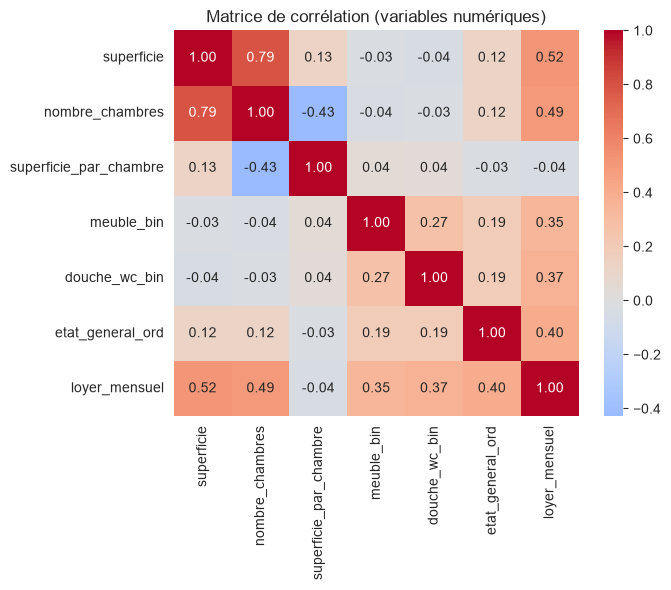

superficie                0.519777
nombre_chambres           0.494954
etat_general_ord          0.398425
douche_wc_bin             0.372223
meuble_bin                0.350530
superficie_par_chambre   -0.042015
Name: loyer_mensuel, dtype: float64

In [53]:
num_cols = ["superficie", "nombre_chambres", "superficie_par_chambre",
            "meuble_bin", "douche_wc_bin", "etat_general_ord"]

corr = df_enc[num_cols + ["loyer_mensuel"]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation (variables numériques)")
plt.tight_layout()
plt.show()

corr["loyer_mensuel"].drop("loyer_mensuel").sort_values(ascending=False)

In [54]:
X_vif = sm.add_constant(df_enc[feature_cols].astype(float))
vif_data = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).sort_values("VIF", ascending=False)
vif_data.head(10)

,feature,VIF
0,const,62.534434
2,nombre_chambres,11.903444
1,superficie,10.035820
3,superficie_par_chambre,4.604029
7,quartier_Ambatobe,2.324882
16,quartier_Ankorondrano,2.229317
11,quartier_Analamahitsy,2.152133
18,quartier_Isoraka,2.147619
19,quartier_Itaosy,2.144682
21,quartier_Tanjombato,2.073273



**Interprétation :** `superficie_par_chambre` est une combinaison linéaire de `superficie` et
`nombre_chambres` : elle est donc fortement redondante avec ces deux variables (VIF le plus
élevé après la constante). On la retire du jeu de variables explicatives. `superficie` et
`nombre_chambres` restent proches du seuil de 10 (elles sont naturellement corrélées entre
elles dans l'immobilier), mais chacune apporte une information individuelle utile ; on les
conserve toutes les deux à ce stade et on laissera l'**élimination arrière (Partie 3)** trancher
statistiquement si l'une d'elles doit être retirée.


In [55]:
feature_cols = [c for c in feature_cols if c != "superficie_par_chambre"]
X = df_enc[feature_cols].astype(float)
y = df_enc["loyer_mensuel"].astype(float)
print(f"Variables explicatives finales retenues : {len(feature_cols)}")

Variables explicatives finales retenues : 23



## 1.8 Standardisation et normalisation — remarque importante

L'énoncé place la standardisation dans la Partie 1. En pratique, il est essentiel de **calculer
les paramètres de standardisation (moyenne, écart-type) uniquement sur les données
d'entraînement**, puis de les appliquer au jeu de test — sinon des informations du test
"fuient" dans l'entraînement (*data leakage*). C'est pourquoi la standardisation est réalisée
juste après la séparation train/test, au tout début de la Partie 2 (§2.2).


# 📌 Partie 2 : Modélisation

## 2.1 Séparation en jeu d'entraînement et de test

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (512, 23) | Test : (129, 23)


## 2.2 Standardisation des variables (fit sur le train uniquement)

In [57]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
X_train_s.describe().T[["mean", "std"]].head()

,mean,std
superficie,1.179612e-16,1.000978
nombre_chambres,-1.908196e-17,1.000978
meuble_bin,4.857226e-17,1.000978
douche_wc_bin,-2.081668e-17,1.000978
etat_general_ord,4.857226e-17,1.000978


## 2.3 Implémentation de la régression linéaire multiple

In [73]:
model = LinearRegression()
model.fit(X_train_s, y_train)
print("Modèle entraîné sur", X_train_s.shape[1], "variables.")

Modèle entraîné sur 23 variables.


## 2.4 Évaluation du modèle : R² et RMSE

In [59]:
y_pred_train = model.predict(X_train_s)
y_pred_test = model.predict(X_test_s)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
rmse_train = mean_squared_error(y_train, y_pred_train) ** 0.5
rmse_test = mean_squared_error(y_test, y_pred_test) ** 0.5

print(f"R²   -> train : {r2_train:.3f} | test : {r2_test:.3f}")
print(f"RMSE -> train : {rmse_train:,.0f} Ar | test : {rmse_test:,.0f} Ar")

R²   -> train : 0.844 | test : 0.830
RMSE -> train : 304,126 Ar | test : 271,292 Ar


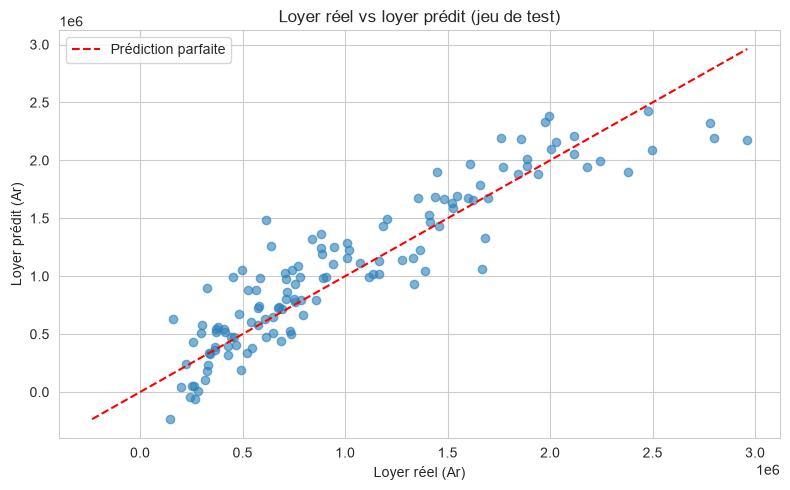

In [60]:
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred_test, alpha=0.6, color="#2980b9")
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
ax.plot(lims, lims, "r--", label="Prédiction parfaite")
ax.set_xlabel("Loyer réel (Ar)")
ax.set_ylabel("Loyer prédit (Ar)")
ax.set_title("Loyer réel vs loyer prédit (jeu de test)")
ax.legend()
plt.tight_layout()
plt.show()


## 2.5 Vérification des hypothèses de la régression linéaire multiple

Une régression linéaire n'est fiable que si certaines hypothèses sur les **résidus** (erreurs de
prédiction) sont à peu près respectées :

1. **Linéarité** : les résidus ne doivent pas montrer de motif particulier par rapport aux
   valeurs prédites.
2. **Normalité** des résidus (histogramme + Q-Q plot + test de Shapiro-Wilk).
3. **Homoscédasticité** : la variance des résidus doit être constante (test de Breusch-Pagan).
4. **Indépendance** des résidus (test de Durbin-Watson, statistique proche de 2 = pas
   d'autocorrélation).
5. **Absence de forte multicolinéarité** entre variables explicatives (déjà vérifié en §1.7
   avec le VIF).


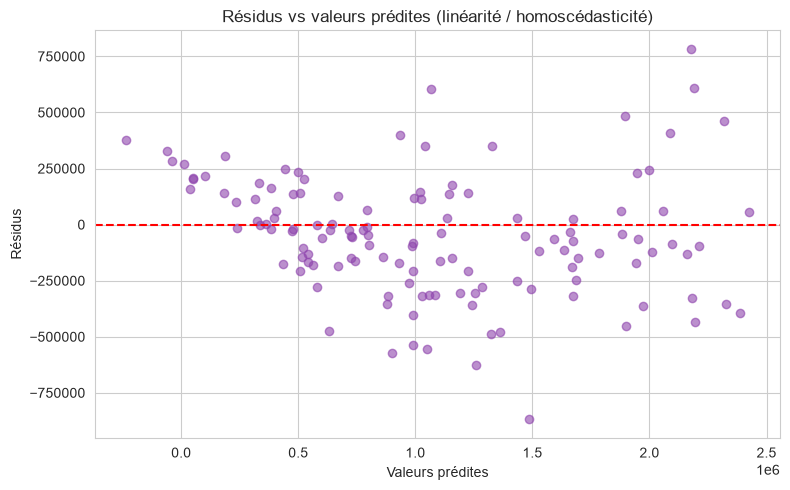

In [61]:
residus = y_test - y_pred_test

fig, ax = plt.subplots()
ax.scatter(y_pred_test, residus, alpha=0.6, color="#8e44ad")
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Valeurs prédites")
ax.set_ylabel("Résidus")
ax.set_title("Résidus vs valeurs prédites (linéarité / homoscédasticité)")
plt.tight_layout()
plt.show()

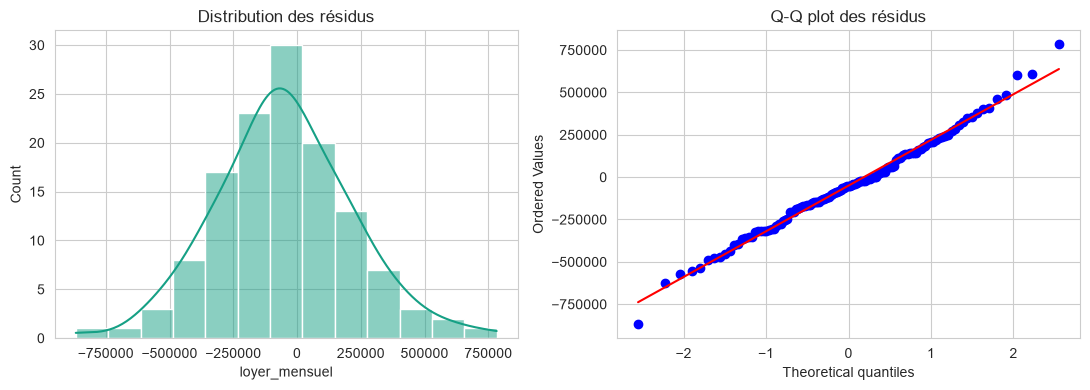

Test de Shapiro-Wilk : statistique=0.993, p-value=0.783
-> On ne rejette pas H0 : les résidus suivent une loi approximativement normale.


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(residus, kde=True, ax=axes[0], color="#16a085")
axes[0].set_title("Distribution des résidus")
stats.probplot(residus, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot des résidus")
plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residus)
print(f"Test de Shapiro-Wilk : statistique={shapiro_stat:.3f}, p-value={shapiro_p:.3f}")
if shapiro_p > 0.05:
    print("-> On ne rejette pas H0 : les résidus suivent une loi approximativement normale.")
else:
    print("-> H0 rejetée : les résidus s'écartent significativement de la normalité.")

In [63]:
dw = durbin_watson(residus)
print(f"Statistique de Durbin-Watson : {dw:.3f} (proche de 2 = pas d'autocorrélation)")

X_test_sm = sm.add_constant(X_test_s)
bp_stat, bp_pvalue, _, _ = het_breuschpagan(residus, X_test_sm)
print(f"Test de Breusch-Pagan : statistique={bp_stat:.3f}, p-value={bp_pvalue:.3f}")
if bp_pvalue > 0.05:
    print("-> On ne rejette pas H0 : la variance des résidus semble constante (homoscédasticité).")
else:
    print("-> H0 rejetée : présence probable d'hétéroscédasticité.")

Statistique de Durbin-Watson : 1.593 (proche de 2 = pas d'autocorrélation)
Test de Breusch-Pagan : statistique=34.741, p-value=0.055
-> On ne rejette pas H0 : la variance des résidus semble constante (homoscédasticité).


# 📌 Partie 3 : Optimisation du modèle


## 3.1 Sélection de variables — Élimination arrière (Backward Elimination)

**Principe :** on part du modèle complet (toutes les variables), on regarde la p-value de
chaque coefficient (test de significativité `H0: coefficient = 0`), et on retire à chaque
itération la variable la **moins significative** (p-value la plus élevée) tant qu'elle dépasse
le seuil de 5%. On s'arrête quand toutes les variables restantes sont statistiquement
significatives.


In [64]:
X_be = sm.add_constant(X_train_s.copy())
current_features = list(X_be.columns)
historique = []

while True:
    ols = sm.OLS(y_train, X_be[current_features]).fit()
    pvals = ols.pvalues.drop("const")
    max_p = pvals.max()
    if max_p > 0.05 and len(pvals) > 1:
        pire_variable = pvals.idxmax()
        historique.append((pire_variable, round(max_p, 4)))
        current_features.remove(pire_variable)
    else:
        break

be_features = [c for c in current_features if c != "const"]

print("Variables retirées (ordre) :")
for var, p in historique:
    print(f"  - {var} (p-value = {p})")
print(f"\n✅ {len(be_features)} variables conservées sur {X_train_s.shape[1]} :")
print(be_features)

Variables retirées (ordre) :
  - type_d_acces_sans (p-value = 0.9)
  - quartier_Analakely (p-value = 0.6651)
  - quartier_Ambohijatovo (p-value = 0.8078)
  - quartier_Isoraka (p-value = 0.6458)
  - quartier_Andravoahangy (p-value = 0.3056)
  - quartier_Ankadifotsy (p-value = 0.1803)
  - quartier_Antaninarenina (p-value = 0.0738)

✅ 16 variables conservées sur 23 :
['superficie', 'nombre_chambres', 'meuble_bin', 'douche_wc_bin', 'etat_general_ord', 'quartier_Ambatobe', 'quartier_Ambohimanarina', 'quartier_Analamahitsy', 'quartier_Andraharo', 'quartier_Ankatso', 'quartier_Ankorondrano', 'quartier_Itaosy', 'quartier_Ivandry', 'quartier_Tanjombato', 'type_d_acces_voiture', 'type_d_acces_voiture_avec_parking']


In [65]:
model_be = LinearRegression().fit(X_train_s[be_features], y_train)
r2_be = r2_score(y_test, model_be.predict(X_test_s[be_features]))
rmse_be = mean_squared_error(y_test, model_be.predict(X_test_s[be_features])) ** 0.5
print(f"Backward elimination -> R² test = {r2_be:.3f} | RMSE test = {rmse_be:,.0f} Ar")

Backward elimination -> R² test = 0.833 | RMSE test = 268,707 Ar



## 3.2 Sélection de variables — RFE (Recursive Feature Elimination)

**Principe :** RFE entraîne le modèle, retire la variable ayant le **plus petit coefficient**
(la moins "influente"), et répète le processus jusqu'à atteindre un nombre de variables cible
fixé à l'avance (ici arbitrairement 10, contre 16 pour l'élimination arrière qui, elle, s'arrête
dès que toutes les variables restantes sont significatives).


In [66]:
rfe = RFE(LinearRegression(), n_features_to_select=10)
rfe.fit(X_train_s, y_train)
rfe_features = list(X_train_s.columns[rfe.support_])
print("Variables retenues par RFE :", rfe_features)

model_rfe = LinearRegression().fit(X_train_s[rfe_features], y_train)
r2_rfe = r2_score(y_test, model_rfe.predict(X_test_s[rfe_features]))
rmse_rfe = mean_squared_error(y_test, model_rfe.predict(X_test_s[rfe_features])) ** 0.5
print(f"RFE -> R² test = {r2_rfe:.3f} | RMSE test = {rmse_rfe:,.0f} Ar")

Variables retenues par RFE : ['superficie', 'nombre_chambres', 'quartier_Ambatobe', 'quartier_Analamahitsy', 'quartier_Andraharo', 'quartier_Ankatso', 'quartier_Ankorondrano', 'quartier_Itaosy', 'quartier_Ivandry', 'quartier_Tanjombato']
RFE -> R² test = 0.725 | RMSE test = 344,960 Ar


## 3.3 Comparaison des modèles

,Modèle,Nb variables,R² test,RMSE test (Ar)
0,Complet (toutes variables),23,0.830027,271292.341236
1,Élimination arrière,16,0.833251,268707.071324
2,RFE (k=10),10,0.725184,344960.114458


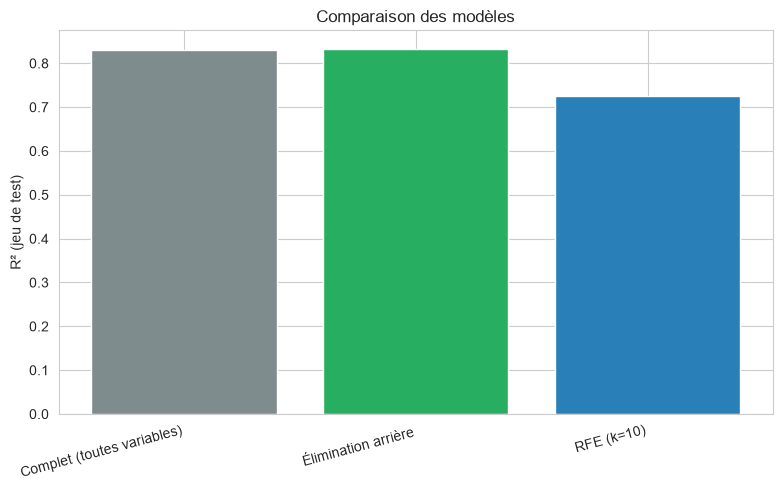

In [67]:
comparatif = pd.DataFrame({
    "Modèle": ["Complet (toutes variables)", "Élimination arrière", "RFE (k=10)"],
    "Nb variables": [X.shape[1], len(be_features), len(rfe_features)],
    "R² test": [r2_test, r2_be, r2_rfe],
    "RMSE test (Ar)": [rmse_test, rmse_be, rmse_rfe],
})
display(comparatif)

fig, ax = plt.subplots()
ax.bar(comparatif["Modèle"], comparatif["R² test"], color=["#7f8c8d", "#27ae60", "#2980b9"])
ax.set_ylabel("R² (jeu de test)")
ax.set_title("Comparaison des modèles")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


**Conclusion :** le modèle par **élimination arrière** obtient le meilleur R² test tout en étant
plus parcimonieux que le modèle complet (moins de variables, donc plus interprétable et moins
sensible au sur-apprentissage). Le RFE, contraint à un nombre de variables fixé arbitrairement à
10, perd en performance car il élimine des variables encore informatives. **On retient donc le
modèle issu de l'élimination arrière comme modèle final.**


## 3.4 Poids des variables du modèle final

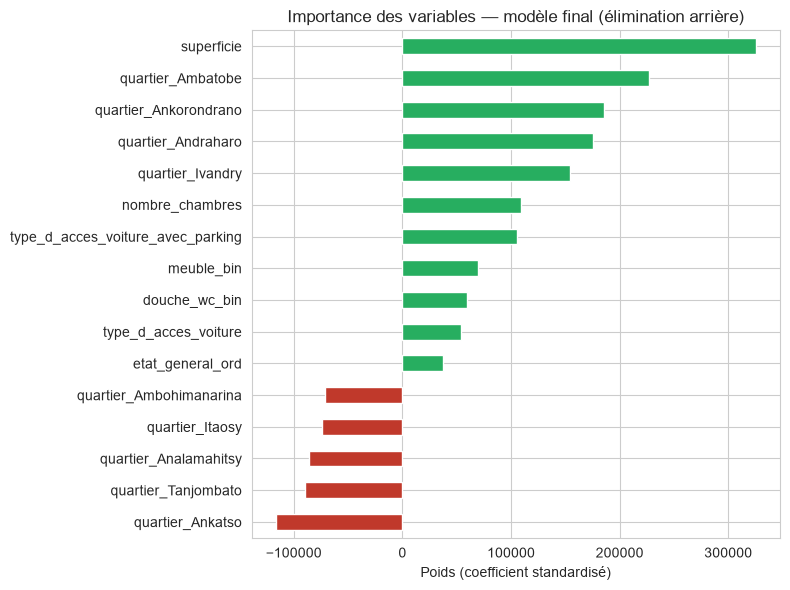

In [68]:
coefs = pd.Series(model_be.coef_, index=be_features).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#c0392b" if v < 0 else "#27ae60" for v in coefs]
coefs.plot(kind="barh", ax=ax, color=colors)
ax.set_xlabel("Poids (coefficient standardisé)")
ax.set_title("Importance des variables — modèle final (élimination arrière)")
plt.tight_layout()
plt.show()


# 📌 Partie 4 : Déploiement d'une application Streamlit

On sauvegarde maintenant tout ce dont l'application aura besoin pour reproduire exactement le
même prétraitement à l'inférence qu'à l'entraînement :

- le **modèle final** (élimination arrière) ;
- le **scaler** (ajusté sur `X_train`, avec l'ordre exact des colonnes brutes) ;
- des **métadonnées** : liste des quartiers, catégorie de référence du one-hot encoding
  (celle supprimée par `drop_first=True`), ordre des états, coordonnées GPS moyennes par
  quartier (pour la carte interactive).

L'application elle-même est fournie dans un fichier séparé **`app.py`**, à lancer avec :

```bash
streamlit run app.py
```


In [69]:
all_quartiers = sorted(df["quartier"].unique())
quartier_dummy_cols = [c for c in feature_cols if c.startswith("quartier_")]
present_q = [c.replace("quartier_", "") for c in quartier_dummy_cols]
quartier_ref = [q for q in all_quartiers if q not in present_q][0]

all_acces = sorted(df["type_d_acces"].unique())
acces_dummy_cols = [c for c in feature_cols if c.startswith("type_d_acces_")]
present_a = [c.replace("type_d_acces_", "") for c in acces_dummy_cols]
acces_ref = [a for a in all_acces if a not in present_a][0]

quartier_centroids = df.groupby("quartier")[["latitude", "longitude"]].mean().round(6).to_dict("index")

meta = {
    "raw_feature_cols": feature_cols,      # ordre exact attendu par le scaler
    "selected_features": be_features,      # variables utilisées par le modèle final
    "quartier_list": all_quartiers,
    "quartier_ref": quartier_ref,          # catégorie de référence (dummies = 0)
    "acces_list": all_acces,
    "acces_ref": acces_ref,
    "etat_order": etat_order,
    "quartier_centroids": quartier_centroids,
    "r2_test": r2_be,
    "rmse_test": rmse_be,
}

joblib.dump(model_be, "model/modele_final.pkl")
joblib.dump(scaler, "model/scaler.pkl")
joblib.dump(meta, "model/meta.pkl")
print("✅ Modèle, scaler et métadonnées sauvegardés dans le dossier model/")

✅ Modèle, scaler et métadonnées sauvegardés dans le dossier model/



## Conclusion & pistes d'amélioration (bonus)

- **Carte interactive** : implémentée dans `app.py` avec `folium` + `streamlit-folium` — un
  clic sur la carte renvoie des coordonnées GPS, converties en quartier par **distance au
  centroïde le plus proche** (simplification documentée : une vraie découpe par polygones
  GeoJSON + `geopandas` serait plus précise mais nécessite des données de zonage officielles
  d'Antananarivo, non disponibles ici).
- **Données additionnelles** : le pipeline est prêt à accueillir de nouvelles colonnes
  (ex. indice de sécurité, distance au centre-ville, niveau de pollution) — il suffirait de les
  ajouter au CSV et à `num_cols` / `feature_cols`.
- **Modèles alternatifs** : on pourrait comparer la régression linéaire à des modèles non
  linéaires (Random Forest, Gradient Boosting) pour voir si la relation superficie/loyer est
  bien captée par un modèle linéaire.
